# Detecção de fraude com PCA, autoencoder e VAE

Estudo do capítulo 20 do *Probabilistic Machine Learning: An Introduction* (Murphy, 2022), aplicado a transações de cartão de crédito.

**Dados:** [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) (Machine Learning Group, ULB). São 284.807 transações feitas com cartões europeus em setembro de 2013, das quais 492 (0,17%) são fraudes. O arquivo tem ~150 MB e não está no repositório: baixe no Kaggle e coloque o `creditcard.csv` na mesma pasta do notebook.

**Detalhe importante sobre o dataset:** por confidencialidade, as colunas `V1` a `V28` já são componentes principais das variáveis originais. Só `Time` e `Amount` vieram sem transformação. Isso muda bastante a interpretação da PCA abaixo.

Roteiro:
1. PCA do zero (§20.1)
2. Autoencoder linear (§20.3.1)
3. Visualizando as fraudes (PCA, autoencoder e t-SNE)
4. Detecção de fraude por erro de reconstrução, sem usar os rótulos no treino

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)

df = pd.read_csv("creditcard.csv")
X_df = df.drop(columns=["Class", "Time"])
y = df["Class"]
X = torch.tensor(X_df.values, dtype=torch.float64)

In [2]:
print(X.shape)
print(y.value_counts())
print("fração de fraudes: %.4f%%" % (100 * y.mean()))

torch.Size([284807, 29])
Class
0    284315
1       492
Name: count, dtype: int64
fração de fraudes: 0.1727%


## 1. PCA do zero (§20.1)

In [3]:
class PCA:
    def __init__(self, n_components, standardize=False):
        self.n_components = n_components
        self.standardize = standardize

    def fit(self, X):
        self.mean_ = X.mean(dim=0)
        X_centered = X - self.mean_
        if self.standardize:
            self.scale_ = X_centered.std(dim=0)
            X_centered = X_centered / self.scale_
        U, S, Vt = torch.linalg.svd(X_centered, full_matrices=False)
        self.components_ = Vt[:self.n_components]
        self.eigenvalues_ = (S ** 2) / X.shape[0]
        return self

    def transform(self, X):
        X_centered = X - self.mean_
        if self.standardize:
            X_centered = X_centered / self.scale_
        return X_centered @ self.components_.T

    def inverse_transform(self, Z):
        X_rec = Z @ self.components_
        if self.standardize:
            X_rec = X_rec * self.scale_
        X_rec = X_rec + self.mean_
        return X_rec

In [4]:
pca = PCA(n_components=29)
pca.fit(X)
Z = pca.transform(X)
X_rec = pca.inverse_transform(Z)
erro = ((X - X_rec) ** 2).mean().item()
print("erro de reconstrução:", erro)

erro de reconstrução: 4.354659272827638e-28


Com as 29 componentes a reconstrução é exata (o erro de ~1e-28 é só arredondamento numérico), o que confirma que a implementação está certa.

In [5]:
# versão 1: sem padronizar
pca_raw = PCA(n_components=29, standardize=False)
pca_raw.fit(X)

# versão 2: com padronizar
pca_std = PCA(n_components=29, standardize=True)
pca_std.fit(X)

print("sem padronizar, autovalores:", pca_raw.eigenvalues_.numpy().round(2)[:5])
print("com padronizar, autovalores:", pca_std.eigenvalues_.numpy().round(3))

sem padronizar, autovalores: [6.256167e+04 3.750000e+00 2.440000e+00 2.200000e+00 2.000000e+00]
com padronizar, autovalores: [1.958 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.    1.    1.    1.    0.042]


In [6]:
V = X_df[[f"V{i}" for i in range(1, 29)]]
corr = V.corr().to_numpy().copy()
np.fill_diagonal(corr, 0)
print("maior |correlação| entre duas colunas V:", np.abs(corr).max().round(4))
print("maior |correlação| entre Amount e uma V:", V.corrwith(X_df["Amount"]).abs().max().round(3))

maior |correlação| entre duas colunas V: 0.0
maior |correlação| entre Amount e uma V: 0.531


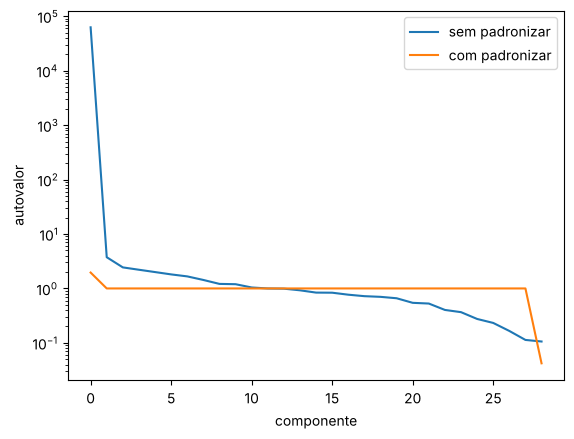

In [7]:
plt.plot(pca_raw.eigenvalues_.numpy(), label="sem padronizar")
plt.plot(pca_std.eigenvalues_.numpy(), label="com padronizar")
plt.yscale("log")
plt.xlabel("componente")
plt.ylabel("autovalor")
plt.legend()
plt.show()

Sem padronizar, o primeiro autovalor (≈ 62.500) é muito maior que os outros porque a coluna `Amount` está numa escala muito maior (valores de até milhares), enquanto as colunas V têm variância entre ~0,1 e ~3,8. A PCA sem padronização basicamente encontra a direção do `Amount`.

Depois de padronizar, quase todos os autovalores ficam exatamente em 1. Isso não é coincidência: como as colunas V já são componentes principais, elas são não correlacionadas entre si (a maior correlação entre duas V é 0). A matriz de correlação das V é a identidade, e a identidade tem todos os autovalores iguais a 1. Os únicos autovalores diferentes vêm do `Amount`, que tem correlação de até 0,53 com algumas V: ele "puxa" o primeiro autovalor para cima (≈ 1,96) e o último para baixo (≈ 0,04).

Ou seja, depois de padronizar sobra pouca estrutura linear para a PCA encontrar: na prática, estamos fazendo PCA em cima de PCA.

## 2. Autoencoder linear (§20.3.1)

Um autoencoder linear treinado com erro quadrático aprende o mesmo subespaço das primeiras componentes da PCA. A diferença é que ele não obriga os eixos a serem ortogonais nem ordenados por variância, e chega lá por gradiente em vez de uma SVD.

In [8]:
import torch.nn as nn

class LinearAutoencoder(nn.Module):
    def __init__(self, n_input, n_bottleneck):
        super().__init__()
        self.encoder = nn.Linear(n_input, n_bottleneck, bias=False)
        self.decoder = nn.Linear(n_bottleneck, n_input, bias=False)

    def forward(self, x):
        z = self.encoder(x)
        x_rec = self.decoder(z)
        return x_rec

In [9]:
torch.manual_seed(0)
modelo = LinearAutoencoder(n_input=29, n_bottleneck=2)
print(modelo)

LinearAutoencoder(
  (encoder): Linear(in_features=29, out_features=2, bias=False)
  (decoder): Linear(in_features=2, out_features=29, bias=False)
)


In [10]:
criterio = nn.MSELoss()
otimizador = torch.optim.Adam(modelo.parameters(), lr=0.01)

In [11]:
modelo = modelo.double()
n_epocas = 200

for epoca in range(n_epocas):
    x_rec = modelo(X)
    perda = criterio(x_rec, X)

    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

    if epoca % 20 == 0:
        print(f"época {epoca}: perda = {perda.item():.4f}")

época 0: perda = 2818.3728


época 20: perda = 1884.7277


época 40: perda = 811.7389


época 60: perda = 26.0020


época 80: perda = 13.3806


época 100: perda = 1.8830


época 120: perda = 1.2657


época 140: perda = 1.1977


época 160: perda = 1.1530


época 180: perda = 1.1294


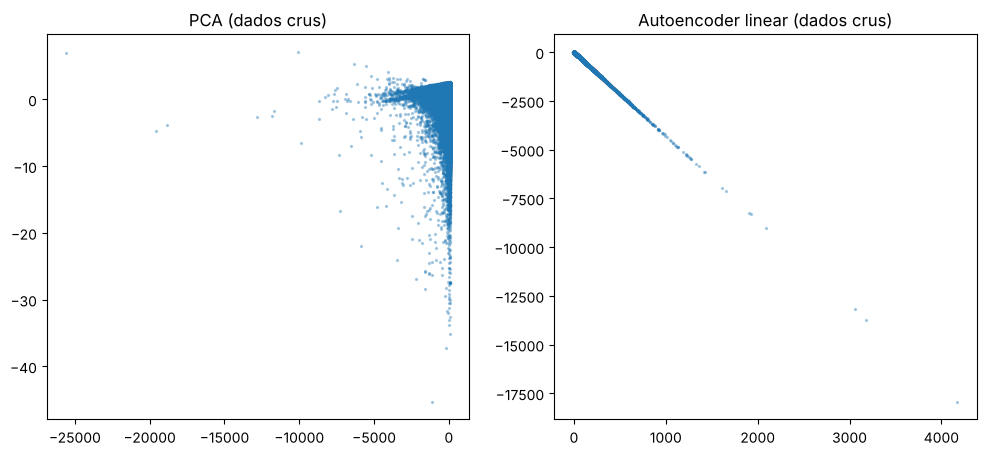

In [12]:
pca2 = PCA(n_components=2, standardize=False)
pca2.fit(X)
Z_pca = pca2.transform(X)
Z_ae = modelo.encoder(X).detach()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.scatter(Z_pca[:, 0], Z_pca[:, 1], s=2, alpha=0.3)
ax1.set_title("PCA (dados crus)")

ax2.scatter(Z_ae[:, 0], Z_ae[:, 1], s=2, alpha=0.3)
ax2.set_title("Autoencoder linear (dados crus)")

plt.show()

Nos dados crus, as duas dimensões do autoencoder caíram praticamente sobre uma reta. O ótimo dele seria o mesmo plano da PCA, mas a variância do `Amount` (≈ 62.500) é tão maior que a da segunda direção (≈ 3,7) que o gradiente quase não empurra a segunda dimensão, e 200 épocas não bastaram (a perda ainda estava caindo). O problema é a escala, não falta de ortogonalidade. A PCA não sofre com isso porque é resolvida de forma exata pela SVD.

In [13]:
X_mean = X.mean(dim=0)
X_std = X.std(dim=0)
X_pad = (X - X_mean) / X_std

print("média (deve ser ~0):", X_pad.mean(dim=0)[:3])
print("desvio (deve ser ~1):", X_pad.std(dim=0)[:3])

média (deve ser ~0): tensor([-2.1954e-18, -1.3622e-17, -2.2853e-17], dtype=torch.float64)
desvio (deve ser ~1): tensor([1.0000, 1.0000, 1.0000], dtype=torch.float64)


In [14]:
torch.manual_seed(0)
modelo_pad = LinearAutoencoder(n_input=29, n_bottleneck=2).double()
otimizador_pad = torch.optim.Adam(modelo_pad.parameters(), lr=0.01)

for epoca in range(n_epocas):
    x_rec = modelo_pad(X_pad)
    perda = criterio(x_rec, X_pad)

    otimizador_pad.zero_grad()
    perda.backward()
    otimizador_pad.step()

    if epoca % 20 == 0:
        print(f"época {epoca}: perda = {perda.item():.4f}")

época 0: perda = 1.1109


época 20: perda = 0.9326


época 40: perda = 0.9190


época 60: perda = 0.9073


época 80: perda = 0.9002


época 100: perda = 0.8983


época 120: perda = 0.8981


época 140: perda = 0.8980


época 160: perda = 0.8980


época 180: perda = 0.8980


In [15]:
# o autoencoder chegou ao mesmo erro da PCA com 2 componentes?
pca2_pad = PCA(n_components=2, standardize=True)
pca2_pad.fit(X)
Z_pca_pad = pca2_pad.transform(X)
X_rec_pca = Z_pca_pad @ pca2_pad.components_          # reconstrução no espaço padronizado
erro_pca = ((X_pad - X_rec_pca) ** 2).mean().item()

with torch.no_grad():
    erro_ae = criterio(modelo_pad(X_pad), X_pad).item()

print(f"erro PCA (2 componentes):  {erro_pca:.4f}")
print(f"erro autoencoder linear:   {erro_ae:.4f}")

erro PCA (2 componentes):  0.8980
erro autoencoder linear:   0.8980


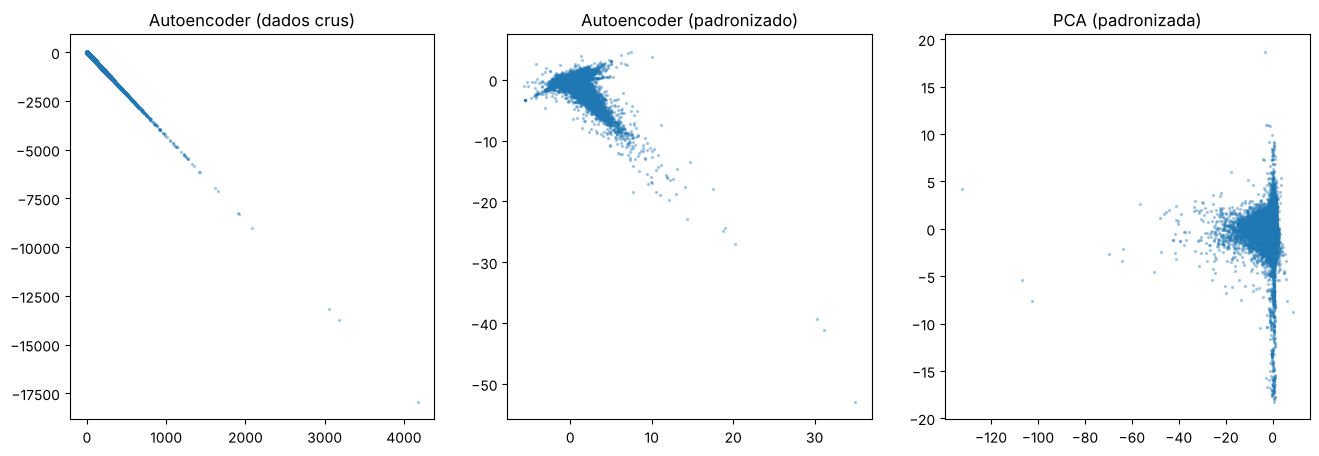

In [16]:
Z_ae_pad = modelo_pad.encoder(X_pad).detach()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

ax1.scatter(Z_ae[:, 0], Z_ae[:, 1], s=2, alpha=0.3)
ax1.set_title("Autoencoder (dados crus)")

ax2.scatter(Z_ae_pad[:, 0], Z_ae_pad[:, 1], s=2, alpha=0.3)
ax2.set_title("Autoencoder (padronizado)")

ax3.scatter(Z_pca_pad[:, 0], Z_pca_pad[:, 1], s=2, alpha=0.3)
ax3.set_title("PCA (padronizada)")

plt.show()

Com os dados padronizados, o erro do autoencoder ficou igual ao da PCA com 2 componentes: ele chegou ao mesmo ótimo, como a teoria prevê.

Mesmo assim, os gráficos do autoencoder e da PCA não são iguais. O motivo é o resultado da seção 1: depois do primeiro, os autovalores são praticamente todos iguais a 1, então a "segunda direção principal" não é única. Qualquer direção dentro desse bloco explica a mesma variância, e cada método escolheu uma diferente. Além disso, o autoencoder pode girar e esticar os eixos sem mudar o erro.

## 3. Visualizando as fraudes

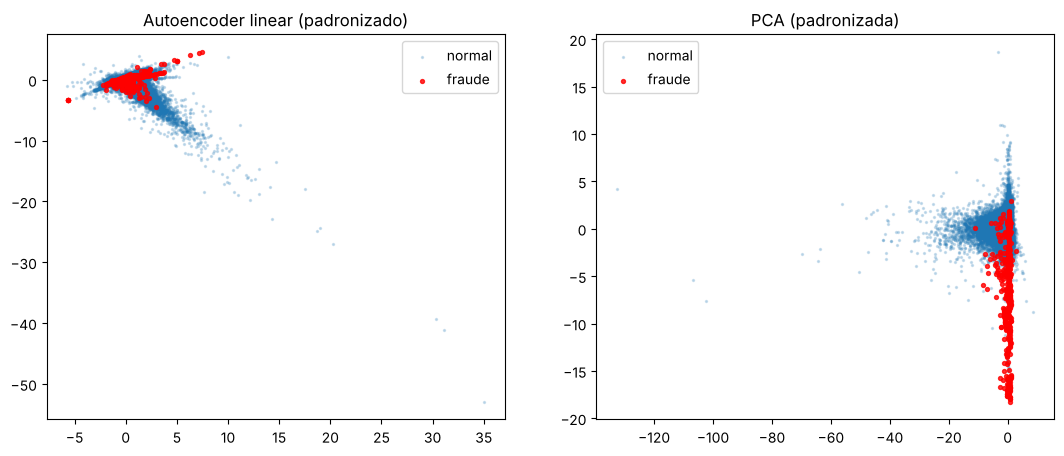

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(Z_ae_pad[y==0, 0], Z_ae_pad[y==0, 1], s=2, alpha=0.2, label="normal")
ax1.scatter(Z_ae_pad[y==1, 0], Z_ae_pad[y==1, 1], s=8, alpha=0.8, color="red", label="fraude")
ax1.set_title("Autoencoder linear (padronizado)")
ax1.legend()

ax2.scatter(Z_pca_pad[y==0, 0], Z_pca_pad[y==0, 1], s=2, alpha=0.2, label="normal")
ax2.scatter(Z_pca_pad[y==1, 0], Z_pca_pad[y==1, 1], s=8, alpha=0.8, color="red", label="fraude")
ax2.set_title("PCA (padronizada)")
ax2.legend()

plt.show()

Na PCA, boa parte das fraudes se afasta da massa de transações normais ao longo do segundo eixo (para baixo). No autoencoder linear isso não aparece, mesmo ele tendo o mesmo erro de reconstrução que a PCA: como os autovalores depois do primeiro são todos ≈ 1, ele escolheu outra direção dentro desse bloco, e essa direção não separa as fraudes. É um bom exemplo de que um gráfico de projeção depende de escolhas que o erro de reconstrução não enxerga. Em todo caso, só olhando o gráfico não dá para dizer o quanto as fraudes são separáveis; isso é medido na seção 4.

### t-SNE (§20.4.10) comparado com a PCA

In [18]:
from sklearn.manifold import TSNE

rng = np.random.default_rng(0)
y_np = y.values
idx_fraude = np.where(y_np == 1)[0]                    # todas as 492
idx_normal = rng.choice(np.where(y_np == 0)[0], 5000, replace=False)
idx = np.concatenate([idx_fraude, idx_normal])

X_sub = X_pad[idx].numpy()      # usa os dados padronizados
y_sub = y_np[idx]
print(X_sub.shape, y_sub.sum())

(5492, 29) 492


In [19]:
tsne = TSNE(n_components=2, perplexity=30, random_state=0)
Z_tsne = tsne.fit_transform(X_sub)
print(Z_tsne.shape)

(5492, 2)


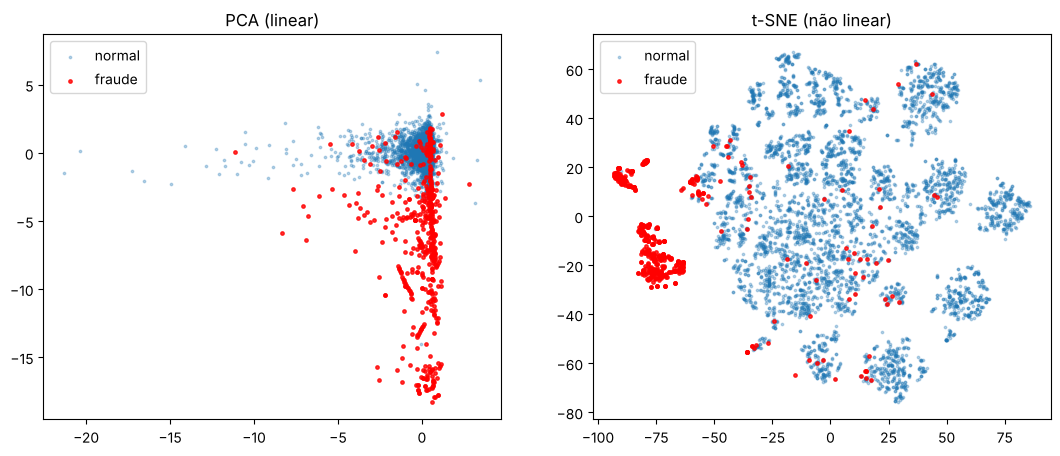

In [20]:
Z_pca_sub = Z_pca_pad[idx].numpy()      # a PCA nos mesmos 5492 pontos

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(Z_pca_sub[y_sub==0, 0], Z_pca_sub[y_sub==0, 1], s=3, alpha=0.3, label="normal")
ax1.scatter(Z_pca_sub[y_sub==1, 0], Z_pca_sub[y_sub==1, 1], s=6, alpha=0.8, color="red", label="fraude")
ax1.set_title("PCA (linear)")
ax1.legend()

ax2.scatter(Z_tsne[y_sub==0, 0], Z_tsne[y_sub==0, 1], s=3, alpha=0.3, label="normal")
ax2.scatter(Z_tsne[y_sub==1, 0], Z_tsne[y_sub==1, 1], s=6, alpha=0.8, color="red", label="fraude")
ax2.set_title("t-SNE (não linear)")
ax2.legend()

plt.show()

Aqui o t-SNE foi aplicado com a implementação do scikit-learn (a minha implementação do zero está no repositório [tsne-do-zero-wholesale](https://github.com/nei-jr/tsne-do-zero-wholesale)), para comparar uma projeção não linear com a PCA. Diferente da PCA, que preserva variância global, o t-SNE converte distâncias em probabilidades de vizinhança e minimiza a divergência KL entre elas, preservando estrutura local. Por ser O(N²), usei um subconjunto de 5.492 pontos (todas as 492 fraudes mais 5.000 normais sorteadas).

O resultado mostra o efeito descrito na §20.4.10.3: o t-SNE forma ilhas compactas e bem separadas. Uma parte grande das fraudes forma ilhas próprias, mas nem todas: algumas ficam espalhadas entre as normais. Isso sugere que existe um tipo de fraude com assinatura bem distinta e outro que se parece com transações normais neste espaço de variáveis.

Lembrando que no t-SNE as distâncias entre ilhas e o tamanho delas não têm significado; só a vizinhança local é preservada.

## 4. Detecção de fraude por erro de reconstrução

Até aqui os gráficos sugerem que as fraudes são diferentes, mas não medem o quanto. A ideia agora é treinar os modelos **só com transações normais**. Eles aprendem a reconstruir bem o padrão normal; uma transação mal reconstruída (erro alto) é suspeita. Os rótulos de fraude só entram no final, para avaliar.

**Por que não usar acurácia:** só 0,17% das transações são fraude, então um "modelo" que diz que nada é fraude acerta 99,83%. Uso duas métricas:

- **Precisão média (average precision, AP):** a área sob a curva precisão × recall. Um ranking aleatório tem AP igual à proporção de fraudes no teste (≈ 0,009).
- **Fraudes entre as 100 transações mais suspeitas:** a pergunta prática de quem vai revisar os alertas.

Divisão: 80% das transações normais para treino; o teste tem os outros 20% das normais mais todas as 492 fraudes. A padronização usa média e desvio só do treino.

In [21]:
from sklearn.metrics import average_precision_score, precision_recall_curve

rng = np.random.default_rng(0)
idx_norm = np.where(y_np == 0)[0]
rng.shuffle(idx_norm)
n_treino = int(0.8 * len(idx_norm))

idx_treino = idx_norm[:n_treino]                                              # só normais
idx_teste  = np.concatenate([idx_norm[n_treino:], np.where(y_np == 1)[0]])    # normais + todas as fraudes
y_teste = y_np[idx_teste]

media_tr, desvio_tr = X[idx_treino].mean(dim=0), X[idx_treino].std(dim=0)
X_tr = (X[idx_treino] - media_tr) / desvio_tr
X_te = (X[idx_teste]  - media_tr) / desvio_tr

print("treino:", tuple(X_tr.shape), "| teste:", tuple(X_te.shape), "| fraudes no teste:", y_teste.sum())
print("AP de um ranking aleatório: %.4f" % y_teste.mean())

def avaliar(nome, score):
    score = np.asarray(score)
    ap = average_precision_score(y_teste, score)
    top100 = y_teste[np.argsort(-score)[:100]].sum()
    print(f"{nome:<26} AP = {ap:.3f} | fraudes no top 100: {top100}")

treino: (227452, 29) | teste: (57355, 29) | fraudes no teste: 492
AP de um ranking aleatório: 0.0086


### 4.1 Distância de Mahalanobis (linha de base)

Antes de qualquer modelo, a pergunta mais simples: quão longe cada transação está do centro das normais, levando em conta a covariância? É a mesma distância que usei para remover outliers no projeto [kmeans-vs-gmm-wholesale](https://github.com/nei-jr/kmeans-vs-gmm-wholesale).

In [22]:
S_inv = torch.linalg.inv(torch.cov(X_tr.T))
D = X_te - X_tr.mean(dim=0)
score_maha = torch.einsum("ij,jk,ik->i", D, S_inv, D).numpy()

avaliar("Mahalanobis", score_maha)

Mahalanobis                AP = 0.710 | fraudes no top 100: 99


### 4.2 PCA

Score = erro de reconstrução usando as k primeiras componentes, ajustadas só nas normais.

In [23]:
pca_tr = PCA(n_components=29).fit(X_tr)
print("autovalores nas normais:", pca_tr.eigenvalues_.numpy().round(2))
print()

def erro_pca(k):
    pca_k = PCA(n_components=k).fit(X_tr)
    X_rec = pca_k.inverse_transform(pca_k.transform(X_te))
    return ((X_te - X_rec) ** 2).sum(dim=1).numpy()

for k in [2, 5, 10, 20, 25, 27]:
    avaliar(f"PCA, k = {k}", erro_pca(k))

autovalores nas normais: [2.01 1.21 1.12 1.1  1.08 1.07 1.06 1.05 1.04 1.03 1.03 1.03 1.02 1.02
 1.01 1.01 1.01 1.   1.   1.   1.   1.   0.99 0.99 0.96 0.96 0.95 0.19
 0.04]



PCA, k = 2                 AP = 0.452 | fraudes no top 100: 82


PCA, k = 5                 AP = 0.464 | fraudes no top 100: 82


PCA, k = 10                AP = 0.500 | fraudes no top 100: 83


PCA, k = 20                AP = 0.572 | fraudes no top 100: 88


PCA, k = 25                AP = 0.636 | fraudes no top 100: 91


PCA, k = 27                AP = 0.807 | fraudes no top 100: 99


Com poucas componentes, a PCA vai mal (AP ≈ 0,45 com k = 2), e melhora conforme k aumenta. Parece contraintuitivo, mas faz sentido: o erro de reconstrução com k componentes é a soma das projeções nas componentes que **ficaram de fora**. Com k = 27, só sobram as duas de menor variância (autovalores ≈ 0,19 e 0,04), justamente as direções em que as transações normais quase não variam. Uma transação que se mexe nessas direções foge muito do padrão normal.

Ou seja: **a fraude aparece nas direções de menor variância, que são exatamente as que a PCA com poucas componentes descarta.** O Mahalanobis faz isso de forma automática, porque divide cada direção pelo seu autovalor: um desvio numa direção de pouca variância pesa muito mais.

Cuidado com o k = 27: ele foi escolhido olhando o resultado no teste, o que seria trapaça num problema real (sem rótulos, não daria para saber qual k usar). O valor dele aqui é explicar o mecanismo, não ser o modelo final. O Mahalanobis não tem esse problema, porque não tem k para escolher.

### 4.3 Autoencoder não linear

Mesma ideia, mas com camadas escondidas e ReLU: 29 → 64 → 8 → 64 → 29. Treino em mini-lotes de 512.

In [24]:
from torch.utils.data import DataLoader, TensorDataset

class Autoencoder(nn.Module):
    def __init__(self, n_input=29, n_hidden=64, n_latent=8):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_input, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_latent))
        self.decoder = nn.Sequential(nn.Linear(n_latent, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_input))

    def forward(self, x):
        return self.decoder(self.encoder(x))

X_tr_f, X_te_f = X_tr.float(), X_te.float()

torch.manual_seed(0)
loader = DataLoader(TensorDataset(X_tr_f), batch_size=512, shuffle=True)
ae = Autoencoder()
otim_ae = torch.optim.Adam(ae.parameters(), lr=1e-3)

for epoca in range(20):
    total = 0
    for (xb,) in loader:
        perda = ((ae(xb) - xb) ** 2).mean()
        otim_ae.zero_grad()
        perda.backward()
        otim_ae.step()
        total += perda.item() * len(xb)
    if epoca % 5 == 0 or epoca == 19:
        print(f"época {epoca}: perda = {total / len(X_tr_f):.4f}")

with torch.no_grad():
    score_ae = ((ae(X_te_f) - X_te_f) ** 2).sum(dim=1).numpy()

avaliar("Autoencoder (latente 8)", score_ae)

época 0: perda = 0.5789


época 5: perda = 0.2345


época 10: perda = 0.1926


época 15: perda = 0.1745


época 19: perda = 0.1658
Autoencoder (latente 8)    AP = 0.601 | fraudes no top 100: 91


### 4.4 VAE (§20.3.5)

Mesma estrutura do VAE que treinei no MNIST, adaptada para dados contínuos: a reconstrução usa verossimilhança gaussiana (erro quadrático) no lugar da Bernoulli, e a saída do decoder não passa por sigmoid. Na hora de pontuar, uso a média μ do encoder, sem sortear z.

In [25]:
class VAE(nn.Module):
    def __init__(self, n_input=29, n_hidden=64, n_latent=8):
        super().__init__()
        self.fc1 = nn.Linear(n_input, n_hidden)
        self.fc_mu = nn.Linear(n_hidden, n_latent)       # produz μ
        self.fc_logvar = nn.Linear(n_hidden, n_latent)   # produz log σ²
        self.fc3 = nn.Linear(n_latent, n_hidden)
        self.fc4 = nn.Linear(n_hidden, n_input)

    def encode(self, x):
        h = torch.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)

    def decode(self, z):
        return self.fc4(torch.relu(self.fc3(z)))         # dados contínuos: sem sigmoid

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


def perda_vae(x_rec, x, mu, logvar):
    recon = 0.5 * ((x_rec - x) ** 2).sum()               # gaussiana com variância 1 (a menos de constante)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + kl


torch.manual_seed(0)
vae = VAE()
otim_vae = torch.optim.Adam(vae.parameters(), lr=1e-3)

for epoca in range(20):
    total = 0
    for (xb,) in loader:
        x_rec, mu, logvar = vae(xb)
        perda = perda_vae(x_rec, xb, mu, logvar)
        otim_vae.zero_grad()
        perda.backward()
        otim_vae.step()
        total += perda.item()
    if epoca % 5 == 0 or epoca == 19:
        print(f"época {epoca}: perda média = {total / len(X_tr_f):.3f}")

with torch.no_grad():
    mu, _ = vae.encode(X_te_f)
    score_vae = ((vae.decode(mu) - X_te_f) ** 2).sum(dim=1).numpy()

avaliar("VAE (latente 8)", score_vae)

época 0: perda média = 14.323


época 5: perda média = 11.438


época 10: perda média = 11.133


época 15: perda média = 11.011


época 19: perda média = 10.910
VAE (latente 8)            AP = 0.799 | fraudes no top 100: 100


### 4.5 Comparação

método                     AP     fraudes no top 100
Mahalanobis                0.710     99
PCA, k = 2                 0.452     82
PCA, k = 27                0.807     99
Autoencoder                0.601     91
VAE                        0.799    100


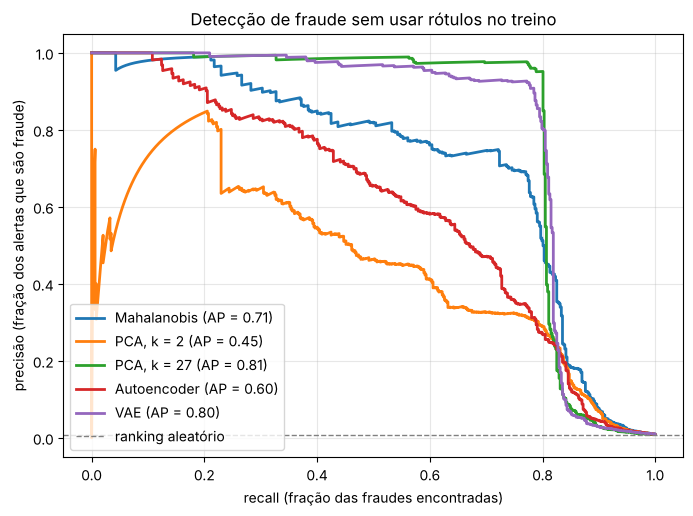

In [26]:
scores = {
    "Mahalanobis": score_maha,
    "PCA, k = 2": erro_pca(2),
    "PCA, k = 27": erro_pca(27),
    "Autoencoder": score_ae,
    "VAE": score_vae,
}

print("método                     AP     fraudes no top 100")
for nome, s in scores.items():
    print(f"{nome:<26} {average_precision_score(y_teste, s):.3f}  {y_teste[np.argsort(-s)[:100]].sum():>5}")

fig, ax = plt.subplots(figsize=(8, 5.5))
for nome, s in scores.items():
    p, r, _ = precision_recall_curve(y_teste, s)
    ax.plot(r, p, lw=2, label=f"{nome} (AP = {average_precision_score(y_teste, s):.2f})")
ax.axhline(y_teste.mean(), color="gray", ls="--", lw=1, label="ranking aleatório")
ax.set_xlabel("recall (fração das fraudes encontradas)")
ax.set_ylabel("precisão (fração dos alertas que são fraude)")
ax.set_title("Detecção de fraude sem usar rótulos no treino")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Conclusões

| método | AP | fraudes no top 100 |
|---|---|---|
| ranking aleatório | 0,009 | ~1 |
| PCA, k = 2 | 0,45 | 82 |
| Autoencoder (latente 8) | 0,60 | 91 |
| Mahalanobis | 0,71 | 99 |
| VAE (latente 8) | 0,80 | 100 |
| PCA, k = 27 (escolhido olhando o teste) | 0,81 | 99 |

- **Sem usar nenhum rótulo no treino**, todos os métodos ficam muito acima do aleatório. Entre as 100 transações mais suspeitas do VAE, as 100 eram fraude, num teste em que só 0,86% das transações são fraude.
- **A linha de base estatística é difícil de bater.** O Mahalanobis, que não tem nada para treinar, ganhou do autoencoder e só perdeu para o VAE.
- **O VAE foi bem melhor que o autoencoder comum**, e isso se manteve com outras sementes (AP entre 0,77 e 0,80 para o VAE e entre 0,56 e 0,64 para o autoencoder, nas sementes 0, 1 e 2). Minha hipótese: o termo KL obriga o espaço latente a ficar perto de uma N(0, I), o que impede o modelo de aprender a reconstruir bem pontos que fogem do padrão; o autoencoder comum, sem essa restrição, generaliza demais e reconstrui parte das fraudes também.
- **Todas as curvas despencam perto de 80% de recall.** Cerca de 20% das fraudes ficam no meio das transações normais em qualquer método, o mesmo que o t-SNE já sugeria. Para pegar essas, um método sem rótulos não basta.

## Próximos passos

- Escolher o tamanho do espaço latente e o número de épocas com um conjunto de validação, em vez de valores fixos.
- Usar os rótulos: comparar com um classificador supervisionado (regressão logística, gradient boosting) e ver quanto a supervisão acrescenta, principalmente nos 20% de fraudes "disfarçadas".
- Usar a coluna `Time`, que ficou de fora.

## Referências

- Murphy, K. P. *Probabilistic Machine Learning: An Introduction*. MIT Press, 2022. Cap. 20.
- Dal Pozzolo, A. et al. *Calibrating Probability with Undersampling for Unbalanced Classification*. IEEE SSCI, 2015. (artigo de origem do dataset)
- Dataset: [Credit Card Fraud Detection – Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)